In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [17]:
df = pd.read_csv("noisy_curvefit_data.csv")

In [18]:
df.shape

(100, 6)

In [19]:
df.head()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


In [20]:
df.tail()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


In [21]:
df.columns

Index(['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5'], dtype='str')

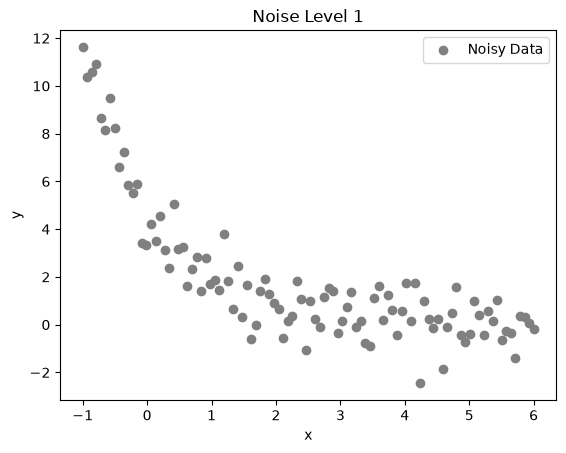

In [22]:
x = df["x"]
y_noise_1 = df["y_noise_1"]

plt.scatter(x, y_noise_1, color="gray", label="Noisy Data")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Noise Level 1")
plt.legend()
plt.show()

In [23]:
def model(x, A, k):
    return A * np.exp(-k * x)

In [24]:
p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)

In [25]:
A_fit, k_fit = popt

In [26]:
print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

Fit: y = 4.71 * e^(-0.92 * x)


In [27]:
residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof
print("Reduced chi-squared:", chi2_reduced)

Reduced chi-squared: 0.7906732087457313


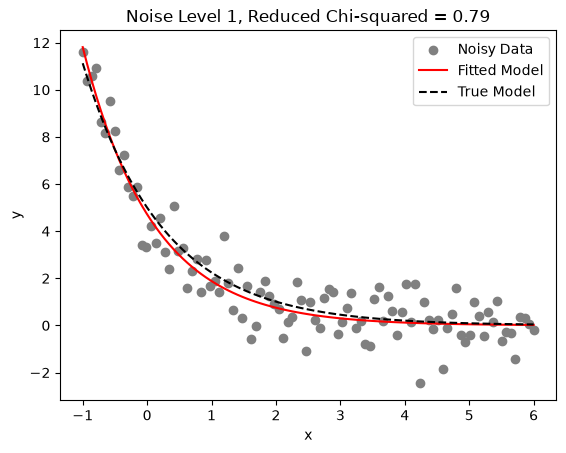

In [28]:
plt.scatter(x, y_noise_1, color="gray", label="Noisy Data")

plt.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted Model")
plt.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True Model")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise Level 1, Reduced Chi-squared = {chi2_reduced:.2f}")

plt.legend()
plt.show()


In [29]:
def fit_model(x, y):
    popt, pcov = curve_fit(model, x, y, p0=[1, 1])
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return popt, chi2_reduced

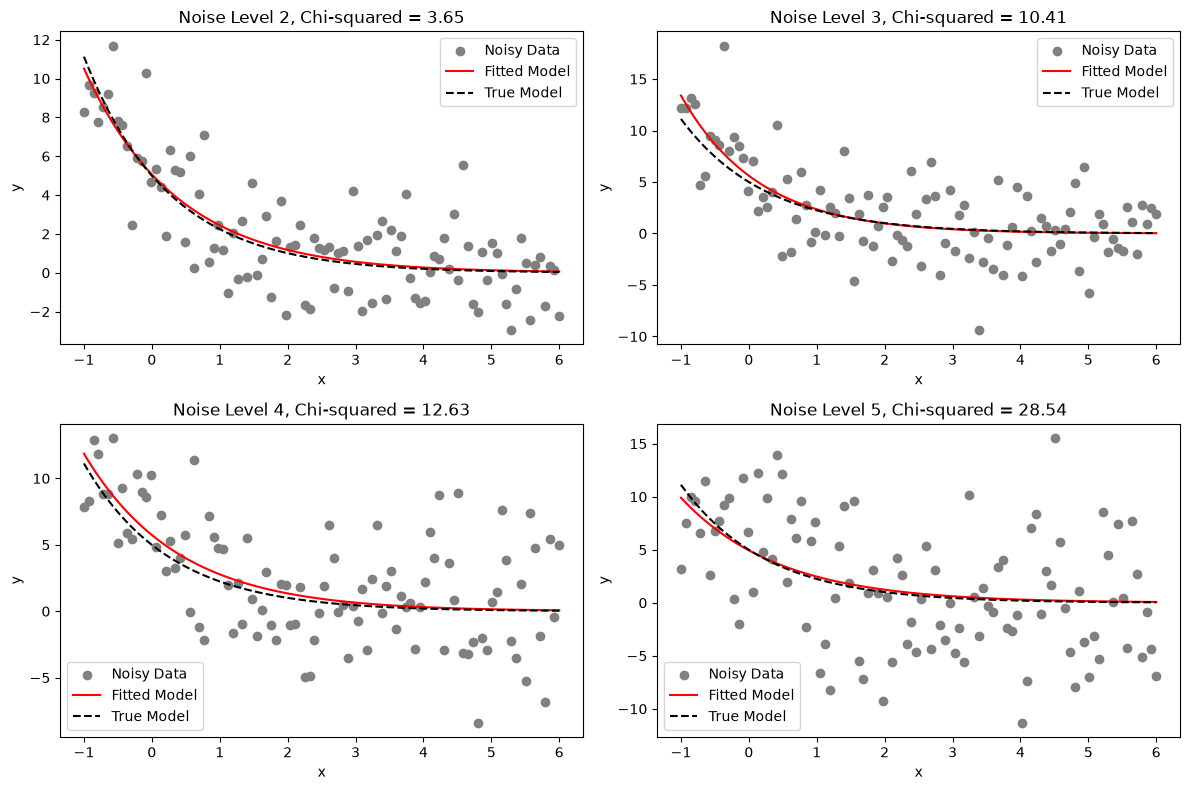

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
noise_levels = ["y_noise_2", "y_noise_3", "y_noise_4", "y_noise_5"]

for i, noise in enumerate(noise_levels):
    y = df[noise]
    popt, chi2_reduced = fit_model(x, y)
    A_fit, k_fit = popt
    ax = axes[i // 2, i % 2]
    ax.scatter(x, y, color="gray", label="Noisy Data")
    ax.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted Model")
    ax.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True Model")
    ax.set_title(f"Noise Level {i+2}, Chi-squared = {chi2_reduced:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

plt.tight_layout()
plt.show()

In [32]:
# The lines are change their shape as the noise level increases. This is because of the increase in data, giving the lines more information to graph itself.
# The reduced chi-squared increases because as the noise level increases, there are more points that are farther away from the fitted model.

In [34]:
results = []
for i, noise in enumerate(["y_noise_1", "y_noise_2", "y_noise_3", "y_noise_4", "y_noise_5"]):
    y = df[noise]
    popt, chi2_reduced = fit_model(x, y)
    A_fit, k_fit = popt
    results.append([i+1, A_fit, k_fit, chi2_reduced])

results_df = pd.DataFrame(results, columns=["Noise Level", "A fit", "k fit", "Reduced chi-squared"])
print(results_df)

   Noise Level     A fit     k fit  Reduced chi-squared
0            1  4.714814  0.918308             0.790673
1            2  5.063889  0.730396             3.649382
2            3  5.609396  0.870372            10.410207
3            4  5.738727  0.725965            12.626832
4            5  4.943458  0.695012            28.538124


In [35]:
results_df.to_csv("noisy_parameters.csv", index=False)

In [36]:
# DONE! (with this one at least)